In [ ]:
#Step 1: Install Necessary Libraries
!pip install yfinance
!pip install --upgrade yfinance==0.2.54

In [ ]:
#Step 2: Import Libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [ ]:
#Step 3: Download Stock Data for Microsoft Corporation (Microsoft Corporation)
data = yf.download("MSFT", start="2004-01-01", end="2024-12-30")
data.head()


[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2004-01-02,17.041077,17.239734,16.966580,17.121781,44487700
2004-01-05,17.469429,17.494262,17.208691,17.214899,67333700
2004-01-06,17.531509,17.556342,17.425973,17.500470,46950800
2004-01-07,17.512882,17.574963,17.388722,17.488051,54298200
2004-01-08,17.481850,17.680507,17.382521,17.624634,58810800


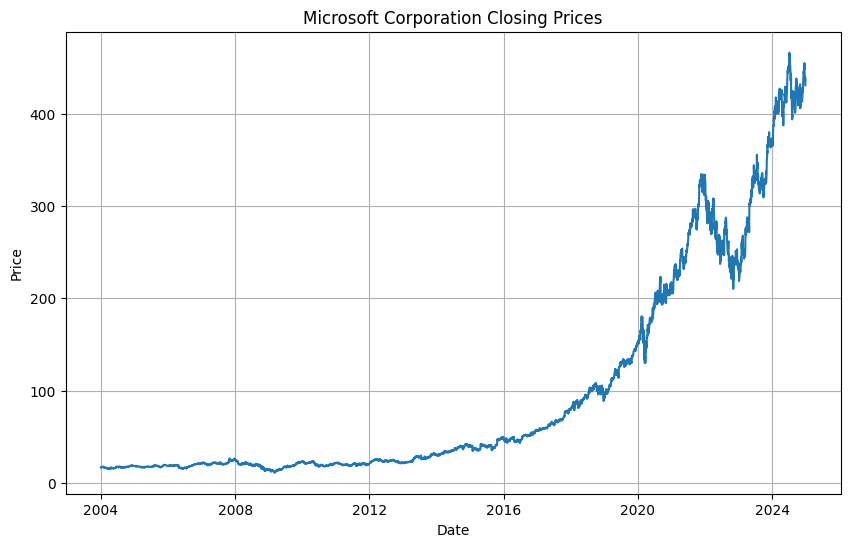

In [ ]:
#Step 4: Visualize Stock Data (Closing Price)
plt.figure(figsize=(10,6))
plt.plot(data['Close'])
plt.title("Microsoft Corporation Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(True)
plt.show()

In [ ]:
#Step 5: Feature Engineering (Target Column)
data['Target'] = data['Close'].shift(-1)

In [ ]:
#Step 6: Drop Rows with Missing Values
data = data.dropna()

In [ ]:
#Step 7: Prepare Data for Prediction
X = data[['Close']] # Features (previous close prices)
Y = data['Target'] # Target (next day's close price)

In [ ]:
#Step 8: Split Data into Training and Testing Sets
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, shuffle=False)

In [ ]:
#Step 9: Train the Linear Regression Model
model_LR = LinearRegression() # Initialize the model
model_LR.fit(X_train, Y_train)

LinearRegression()

In [ ]:
#Step 10: Make Predictions
predictions = model_LR.predict(X_test)

In [ ]:
#Step 11: Evaluate the Model
mae = mean_absolute_error(Y_test, predictions)
mse = mean_squared_error(Y_test, predictions)
print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")

Mean Absolute Error: 3.619901428627253
Mean Squared Error: 23.39440819813315


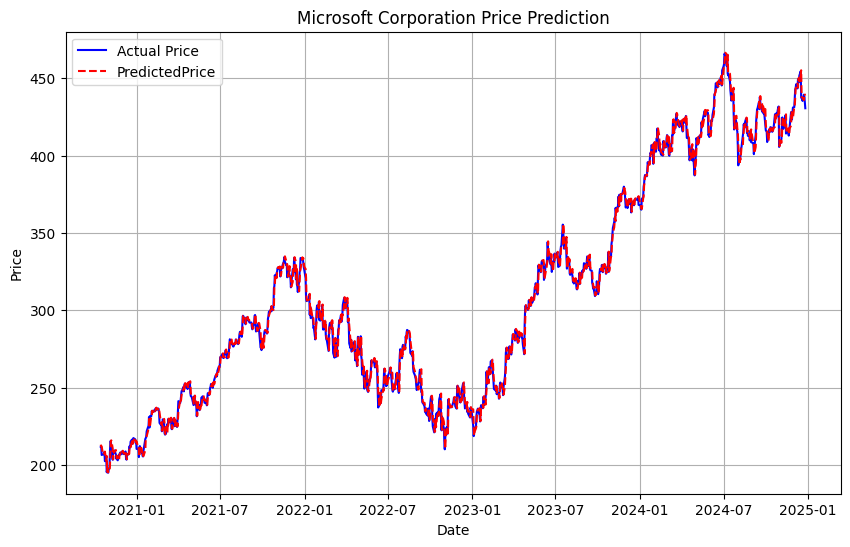

In [ ]:
#Step 12: Visualize Predictions vs. Actual Prices
plt.figure(figsize=(10,6))
plt.plot(Y_test.index, Y_test, label="Actual Price",color='blue')
plt.plot(Y_test.index, predictions, label="PredictedPrice", color='r', linestyle='dashed')
plt.title("Microsoft Corporation Price Prediction")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Step 13: Predict for JUNE 2025
future_dates = pd.date_range(start="2025-06-01",end="2025-06-30", freq="B") # Business days
future_days = (future_dates - data.index[0]).days #Convert to number of days since the start

In [ ]:
#Step 14: Reshape for Model Prediction
future_days = np.array(future_days).reshape(-1, 1)

In [ ]:
#Step 15: Make Future Predictions
future_predictions = model_LR.predict(future_days)

In [ ]:
#Step 16: Store Predictions in a DataFrame
future_predictions_df = pd.DataFrame({ 'Date': future_dates, 'Predicted Close': future_predictions.flatten()})

In [ ]:
#Step 17: Display Predicted Stock Prices
print(future_predictions_df)

         Date  Predicted Close
0  2025-06-02      7832.591886
1  2025-06-03      7833.593242
2  2025-06-04      7834.594598
3  2025-06-05      7835.595954
4  2025-06-06      7836.597310
5  2025-06-09      7839.601378
6  2025-06-10      7840.602734
7  2025-06-11      7841.604090
8  2025-06-12      7842.605446
9  2025-06-13      7843.606802
10 2025-06-16      7846.610870
11 2025-06-17      7847.612226
12 2025-06-18      7848.613582
13 2025-06-19      7849.614938
14 2025-06-20      7850.616294
15 2025-06-23      7853.620362
16 2025-06-24      7854.621718
17 2025-06-25      7855.623074
18 2025-06-26      7856.624430
19 2025-06-27      7857.625786
20 2025-06-30      7860.629854
